In [1]:
from pathlib import Path


import gc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from equipo52_module.config import (
    PROCESSED_DATA_DIR,
    NOMENCLATURA_FILE,
    ESTACIONES_EXCLUIDAS,
    FECHA_INICIO,
    FECHA_FIN,
    VIAJES_FILE,
    NOMENCLATURA_FILE,
    
)

# Verificar que existan los archivos
print(f"Archivo de viajes: {VIAJES_FILE}")
print(f"Existe el Parquet: {VIAJES_FILE.exists()}")
print(f"Existe la nomenclatura: {NOMENCLATURA_FILE.exists()}")

# Cargar los datos
viajes = pd.read_parquet(VIAJES_FILE)

print(f"\nDimensiones: {viajes.shape}")
display(viajes.head())

2026-10-15 20:44:40.717 | INFO     | equipo52_module.config:<module>:11 - PROJ_ROOT path is: C:\Users\ingda\Documents\5_Tec Maestría IA\7_MLOps\Semana 5\equipo52_proyecto_mibici


Archivo de viajes: C:\Users\ingda\Documents\5_Tec Maestría IA\7_MLOps\Semana 5\equipo52_proyecto_mibici\data\interim\viajes.parquet
Existe el Parquet: True
Existe la nomenclatura: True

Dimensiones: (39078984, 5)


,Viaje_Id,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,4601,2014-12-01 00:33:47,2014-12-01 00:36:54,47,47
1,4604,2014-12-01 01:06:54,2014-12-01 01:08:45,5,5
2,4628,2014-12-01 09:47:20,2014-12-01 09:47:47,79,79
3,4631,2014-12-01 09:48:23,2014-12-01 09:48:37,79,79
4,4632,2014-12-01 09:48:46,2014-12-01 09:48:57,79,79


In [2]:
viajes.info()

print("\nValores faltantes:")
display(viajes.isna().sum())

print("\nResumen estadístico:")
display(viajes.describe(include="all").T)

print("\nPeriodo disponible:")
print("Inicio:", viajes["Inicio_del_viaje"].min())
print("Fin:", viajes["Fin_del_viaje"].max())

<class 'pandas.DataFrame'>
RangeIndex: 39078984 entries, 0 to 39078983
Data columns (total 5 columns):
 #   Column            Dtype         
---  ------            -----         
 0   Viaje_Id          int64         
 1   Inicio_del_viaje  datetime64[us]
 2   Fin_del_viaje     datetime64[us]
 3   Origen_Id         int64         
 4   Destino_Id        int64         
dtypes: datetime64[us](2), int64(3)
memory usage: 1.5 GB

Valores faltantes:


Viaje_Id            0
Inicio_del_viaje    0
Fin_del_viaje       0
Origen_Id           0
Destino_Id          0
dtype: int64


Resumen estadístico:


,count,mean,min,25%,50%,75%,max,std
Viaje_Id,39078984.0,23383117.516984,4601.0,11772536.75,23526819.5,35019317.25,46255558.0,13360575.677449
Inicio_del_viaje,39078984,2022-01-17 22:28:13.431700,2014-12-01 00:33:47,2019-07-04 17:55:58,2022-05-16 16:56:15.500000,2024-08-06 09:00:30.250000,2026-09-30 23:59:48,NaN
Fin_del_viaje,39078984,2022-01-17 22:42:37.916890,2014-12-01 00:36:54,2019-07-04 18:06:33,2022-05-16 17:06:16,2024-08-06 09:09:45,2026-10-01 00:14:52,NaN
Origen_Id,39078984.0,133.512595,2.0,50.0,94.0,207.0,519.0,100.149426
Destino_Id,39078984.0,133.342513,2.0,50.0,86.0,212.0,519.0,102.04332



Periodo disponible:
Inicio: 2014-12-01 00:33:47
Fin: 2026-10-01 00:14:52


Analizar la duración y los viajes de la misma estación:

In [3]:
# Calcular la duración de cada viaje en segundos
duracion = (
    viajes["Fin_del_viaje"] - viajes["Inicio_del_viaje"]
).dt.total_seconds()

# Identificar los criterios de revisión
duracion_negativa = duracion < 0
duracion_menor_60 = duracion < 60
duracion_igual_60 = duracion == 60
mismo_origen_destino = viajes["Origen_Id"].eq(viajes["Destino_Id"])

# Resumen de calidad de datos
total = len(viajes)

print(f"Total de viajes: {total:,}")
print(
    f"Duración negativa: {duracion_negativa.sum():,} "
    f"({duracion_negativa.mean():.2%})"
)
print(
    f"Duración menor a 60 segundos: {duracion_menor_60.sum():,} "
    f"({duracion_menor_60.mean():.2%})"
)
print(
    f"Duración exactamente de 60 segundos: {duracion_igual_60.sum():,} "
    f"({duracion_igual_60.mean():.2%})"
)
print(
    f"Mismo origen y destino: {mismo_origen_destino.sum():,} "
    f"({mismo_origen_destino.mean():.2%})"
)

# Analizar la relación entre duración y estación de origen/destino
print("\nViajes con origen y destino iguales:")
print(f"  Menos de 60 segundos: {(mismo_origen_destino & duracion_menor_60).sum():,}")
print(f"  60 segundos o más: {(mismo_origen_destino & ~duracion_menor_60).sum():,}")

print("\nEstadísticas de duración (segundos):")
display(duracion.describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

Total de viajes: 39,078,984
Duración negativa: 0 (0.00%)
Duración menor a 60 segundos: 1,269,425 (3.25%)
Duración exactamente de 60 segundos: 24,340 (0.06%)
Mismo origen y destino: 2,725,187 (6.97%)

Viajes con origen y destino iguales:
  Menos de 60 segundos: 1,205,688
  60 segundos o más: 1,519,499

Estadísticas de duración (segundos):


count    3.907898e+07
mean     8.644852e+02
std      4.559569e+04
min      0.000000e+00
1%       1.400000e+01
5%       1.290000e+02
25%      3.440000e+02
50%      5.650000e+02
75%      8.810000e+02
95%      1.447000e+03
99%      1.985000e+03
max      3.775373e+07
dtype: float64

Revisar los viajes de duración extrema:
para medir cuántos viajes superan distintos umbrales y revisar los diez más largos.

In [4]:
# Umbrales exploratorios
umbrales = {
    "Más de 24 horas": 24 * 60 * 60,
    "Más de 7 días": 7 * 24 * 60 * 60,
    "Más de 30 días": 30 * 24 * 60 * 60,
}

for etiqueta, segundos in umbrales.items():
    cantidad = (duracion > segundos).sum()
    print(f"{etiqueta}: {cantidad:,} ({cantidad / len(viajes):.4%})")

# Revisar los 10 viajes de mayor duración
indices_largos = duracion.nlargest(10).index

viajes_largos = viajes.loc[
    indices_largos,
    [
        "Viaje_Id",
        "Inicio_del_viaje",
        "Fin_del_viaje",
        "Origen_Id",
        "Destino_Id",
    ],
].copy()

viajes_largos["Duracion_segundos"] = duracion.loc[indices_largos]
viajes_largos["Duracion_dias"] = viajes_largos["Duracion_segundos"] / 86400

display(viajes_largos.sort_values("Duracion_segundos", ascending=False))

Más de 24 horas: 1,832 (0.0047%)
Más de 7 días: 1,214 (0.0031%)
Más de 30 días: 861 (0.0022%)


,Viaje_Id,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,Duracion_segundos,Duracion_dias
2098408,2602375,2017-04-22 20:38:32,2018-07-03 19:47:18,221,221,37753726.0,436.964421
2578204,3164209,2017-07-03 21:09:41,2018-07-04 11:39:42,159,159,31588201.0,365.604178
1055132,1380849,2016-09-30 11:13:57,2017-07-29 12:57:42,176,73,26099025.0,302.072049
1055167,1380888,2016-09-30 11:23:52,2017-07-29 09:55:22,192,12,26087490.0,301.938542
1099141,1432504,2016-10-11 14:22:18,2017-07-29 14:39:31,227,75,25143433.0,291.011956
1136412,1476372,2016-10-20 08:35:50,2017-07-31 13:23:06,197,244,24554836.0,284.199491
1142775,1483900,2016-10-21 13:42:27,2017-07-29 12:57:44,66,73,24275717.0,280.968947
1213017,1566448,2016-11-06 17:39:45,2017-08-02 15:53:12,136,8,23235207.0,268.926007
1220319,1575201,2016-11-08 09:37:59,2017-07-31 07:29:20,63,173,22888281.0,264.910660
1233369,1590904,2016-11-10 17:51:49,2017-07-31 09:39:37,212,201,22693668.0,262.658194


Revisar la nomenclatura de estaciones: 
Para identificar qué estaciones aparecen en los viajes y cuáles están en la nomenclatura vigente.

In [5]:
# Cargar nomenclatura de estaciones
nomenclatura = pd.read_csv(NOMENCLATURA_FILE)

print("Dimensiones de la nomenclatura:", nomenclatura.shape)
print("\nColumnas disponibles:")
print(nomenclatura.columns.tolist())

display(nomenclatura.head())

Dimensiones de la nomenclatura: (484, 5)

Columnas disponibles:
['id', 'name', 'latitude', 'longitude', 'dpcapacity']


,id,name,latitude,longitude,dpcapacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


Validar los identificadores de estaciones:
Para comprobar qué identificadores aparecen en los viajes, cuáles faltan en la nomenclatura y cuántos registros están relacionados con las 14 estaciones excluidas por acuerdo del equipo.

In [6]:
# Conjuntos de identificadores
estaciones_nomenclatura = set(nomenclatura["id"].dropna().astype(int))
estaciones_origen = set(viajes["Origen_Id"].unique())
estaciones_destino = set(viajes["Destino_Id"].unique())

estaciones_viajes = estaciones_origen | estaciones_destino

# Estaciones presentes en los viajes, pero ausentes de la nomenclatura
estaciones_sin_nomenclatura = sorted(
    estaciones_viajes - estaciones_nomenclatura
)

# Estaciones de la nomenclatura que no aparecen en los viajes
estaciones_sin_viajes = sorted(
    estaciones_nomenclatura - estaciones_viajes
)

print(f"Estaciones distintas en los viajes: {len(estaciones_viajes)}")
print(f"Estaciones en la nomenclatura: {len(estaciones_nomenclatura)}")

print("\nIdentificadores sin nomenclatura:")
print(estaciones_sin_nomenclatura)

print("\nEstaciones de la nomenclatura que no aparecen en los viajes:")
print(estaciones_sin_viajes)

# Cuantificar los viajes relacionados con las estaciones excluidas
excluidas = set(ESTACIONES_EXCLUIDAS)

origen_excluido = viajes["Origen_Id"].isin(excluidas)
destino_excluido = viajes["Destino_Id"].isin(excluidas)

viajes_con_estacion_excluida = origen_excluido | destino_excluido

print("\nViajes relacionados con estaciones excluidas:")
print(f"Origen en estación excluida: {origen_excluido.sum():,}")
print(f"Destino en estación excluida: {destino_excluido.sum():,}")
print(
    "Viajes afectados (sin contar dos veces los que cumplen ambas): "
    f"{viajes_con_estacion_excluida.sum():,}"
)

Estaciones distintas en los viajes: 486
Estaciones en la nomenclatura: 484

Identificadores sin nomenclatura:
[np.int64(124), np.int64(405), np.int64(407)]

Estaciones de la nomenclatura que no aparecen en los viajes:
[492]

Viajes relacionados con estaciones excluidas:
Origen en estación excluida: 86,110
Destino en estación excluida: 80,003
Viajes afectados (sin contar dos veces los que cumplen ambas): 158,811


Se crea un conjunto de datos específico para P1, sin modificar el Parquet original. Esta celda aplica los filtros de fechas, duración y estaciones excluidas. Por ahora conserva los viajes cuyo origen y destino son iguales, para analizarlos por separado.

In [7]:
# Filtros para P1
fecha_inicio = pd.Timestamp(FECHA_INICIO)
fecha_fin = pd.Timestamp(FECHA_FIN) + pd.Timedelta(days=1)

# Duración del viaje en segundos
duracion = (
    viajes["Fin_del_viaje"] - viajes["Inicio_del_viaje"]
).dt.total_seconds()

# Condiciones de filtrado
mascara_fecha = (
    (viajes["Inicio_del_viaje"] >= fecha_inicio) &
    (viajes["Inicio_del_viaje"] < fecha_fin)
)

mascara_duracion = duracion >= 60

estaciones_excluidas = set(ESTACIONES_EXCLUIDAS)

mascara_estaciones = (
    ~viajes["Origen_Id"].isin(estaciones_excluidas) &
    ~viajes["Destino_Id"].isin(estaciones_excluidas)
)

# Aplicar filtros
mascara_p1 = mascara_fecha & mascara_duracion & mascara_estaciones

print(f"Viajes originales: {len(viajes):,}")
print(f"Fuera del periodo: {(~mascara_fecha).sum():,}")
print(f"Duración menor a 60 segundos: {(~mascara_duracion).sum():,}")
print(f"Relacionados con estaciones excluidas: {(~mascara_estaciones).sum():,}")
print(f"Viajes que cumplen todos los filtros: {mascara_p1.sum():,}")

Viajes originales: 39,078,984
Fuera del periodo: 0
Duración menor a 60 segundos: 1,269,425
Relacionados con estaciones excluidas: 158,811
Viajes que cumplen todos los filtros: 37,653,874


Análisis de los viajes con origen y destino iguales

¿Por qué importa?
Si el objetivo es predecir la cantidad de viajes que comienzan en cada estación, un viaje con origen y destino iguales también puede representar demanda registrada. No conviene asumir que es un error sin investigar su significado.

In [8]:
# Identificar viajes cuyo origen y destino son iguales
mascara_mismo_origen = viajes["Origen_Id"].eq(viajes["Destino_Id"])

# Contar estos viajes antes y después de los filtros
mismo_origen_original = mascara_mismo_origen.sum()
mismo_origen_filtrado = (mascara_p1 & mascara_mismo_origen).sum()

# Calcular proporción en el conjunto filtrado
total_filtrado = mascara_p1.sum()
porcentaje_mismo_origen = (
    mismo_origen_filtrado / total_filtrado * 100
)

print(f"Viajes con origen = destino en datos originales: "
      f"{mismo_origen_original:,}")

print(f"Viajes con origen = destino después de los filtros: "
      f"{mismo_origen_filtrado:,}")

print(f"Porcentaje en el conjunto filtrado: "
      f"{porcentaje_mismo_origen:.2f}%")

Viajes con origen = destino en datos originales: 2,725,187
Viajes con origen = destino después de los filtros: 1,516,068
Porcentaje en el conjunto filtrado: 4.03%


Estos resultados son importantes para documentar la limpieza de datos de P1. Después de aplicar los filtros, quedan 1,516,068 viajes con el mismo origen y destino, equivalentes al 4.03 % del conjunto filtrado.
Se conservarán por ahora. 

Como el objetivo es predecir la demanda de viajes que comienzan en cada estación, estos registros siguen representando inicios registrados. Aunque podrían corresponder a intentos fallidos o anomalías, no tenemos evidencia suficiente para afirmar que todos sean errores.

In [9]:
# Crear la carpeta si todavía no existe
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Crear el conjunto filtrado sin modificar el original
viajes_p1 = viajes.loc[mascara_p1].copy()

# Guardar el resultado
archivo_p1 = PROCESSED_DATA_DIR / "viajes_p1_filtrados.parquet"
viajes_p1.to_parquet(archivo_p1, index=False)

print(f"Archivo guardado en: {archivo_p1}")
print(f"Dimensiones del conjunto P1: {viajes_p1.shape}")
print(f"Tamaño en memoria: {viajes_p1.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"Archivo creado: {archivo_p1.exists()}")

Archivo guardado en: C:\Users\ingda\Documents\5_Tec Maestría IA\7_MLOps\Semana 5\equipo52_proyecto_mibici\data\processed\viajes_p1_filtrados.parquet
Dimensiones del conjunto P1: (37653874, 5)
Tamaño en memoria: 1723.66 MB
Archivo creado: True


Por ahora, no eliminamos los viajes menores de 60 segundos ni los que tienen el mismo origen y destino. Dejamos esas decisiones pendientes hasta observar mejor los patrones de los datos.

Para P1, necesitamos entender cómo cambia la demanda a lo largo del tiempo antes de elegir la granularidad de predicción. Comenzaremos por el número de viajes por mes y por año.

Los días de la semana se codifican de 0 (lunes) a 6 (domingo).

In [10]:
# Crear variables temporales para el EDA
viajes_p1["Anio"] = viajes_p1["Inicio_del_viaje"].dt.year
viajes_p1["Mes"] = viajes_p1["Inicio_del_viaje"].dt.month
viajes_p1["Dia_semana"] = viajes_p1["Inicio_del_viaje"].dt.dayofweek
viajes_p1["Hora"] = viajes_p1["Inicio_del_viaje"].dt.hour

# Revisar el resultado
display(
    viajes_p1[
        ["Inicio_del_viaje", "Anio", "Mes", "Dia_semana", "Hora"]
    ].head()
)

,Inicio_del_viaje,Anio,Mes,Dia_semana,Hora
0,2014-12-01 00:33:47,2014,12,0,0
1,2014-12-01 01:06:54,2014,12,0,1
27,2014-12-01 12:10:13,2014,12,0,12
28,2014-12-01 12:11:29,2014,12,0,12
33,2014-12-01 12:15:08,2014,12,0,12


Como el conjunto tiene más de 37 millones de registros, agruparemos directamente por mes y evitaremos crear copias adicionales de todo el DataFrame.

,Mes,Numero_viajes
0,2014-12,21655
1,2015-01,29939
2,2015-02,30882
3,2015-03,33839
4,2015-04,33316


,Mes,Numero_viajes
137,2026-05,305118
138,2026-06,337578
139,2026-07,371630
140,2026-08,376321
141,2026-09,471090


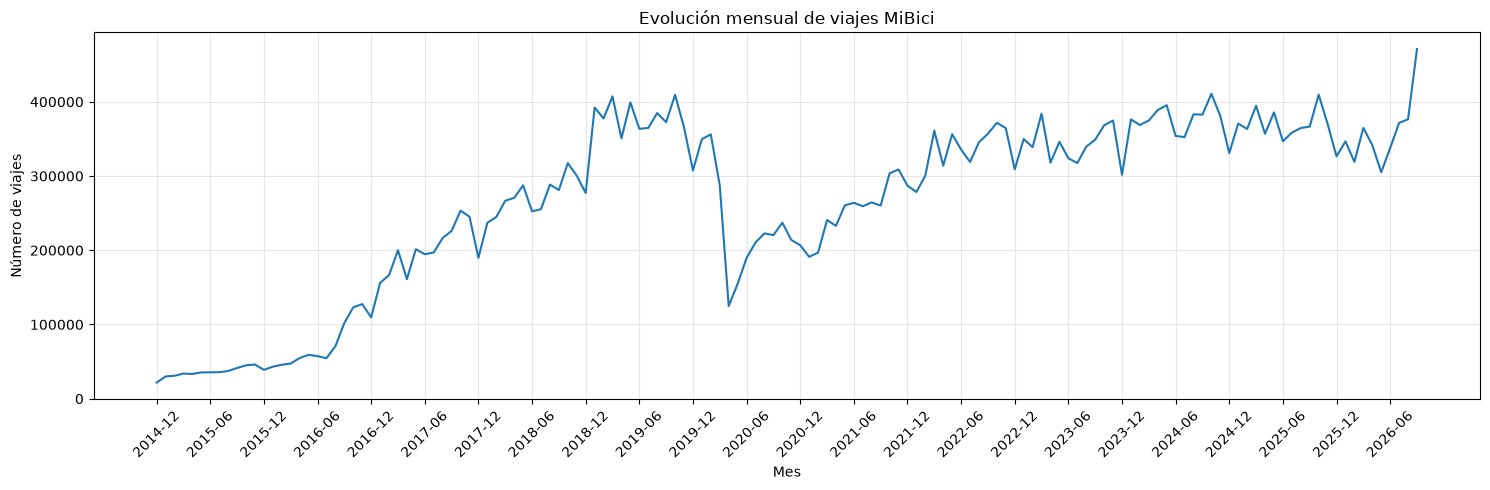

In [11]:
# Conteo de viajes por mes
viajes_mensuales = (
    viajes_p1
    .groupby(viajes_p1["Inicio_del_viaje"].dt.to_period("M"))
    .size()
    .rename("Numero_viajes")
    .reset_index()
)

viajes_mensuales = viajes_mensuales.rename(
    columns={"Inicio_del_viaje": "Mes"}
)

viajes_mensuales["Mes"] = viajes_mensuales["Mes"].astype(str)

display(viajes_mensuales.head())
display(viajes_mensuales.tail())

plt.figure(figsize=(15, 5))
plt.plot(
    viajes_mensuales["Mes"],
    viajes_mensuales["Numero_viajes"]
)
plt.title("Evolución mensual de viajes MiBici")
plt.xlabel("Mes")
plt.ylabel("Número de viajes")
plt.xticks(
    range(0, len(viajes_mensuales), 6),
    viajes_mensuales["Mes"].iloc[::6],
    rotation=45
)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

La evolución mensual de los viajes de MiBici muestra una tendencia general de crecimiento desde el inicio del registro en diciembre de 2014 hasta septiembre de 2026, lo que sugiere un aumento en el uso del sistema a lo largo del tiempo. Sin embargo, este crecimiento no ha sido constante. Durante el periodo de la pandemia de COVID-19 se observa una disminución de la actividad, seguida de una recuperación progresiva en los años posteriores. También se aprecian variaciones entre meses que podrían estar relacionadas con la estacionalidad, las condiciones de movilidad y la disponibilidad de estaciones. Estos patrones son relevantes para el proyecto P1, ya que el modelo de predicción deberá considerar tanto la tendencia de largo plazo como las fluctuaciones temporales para estimar adecuadamente la demanda por estación.

Analisis de la demanda por día de la semana

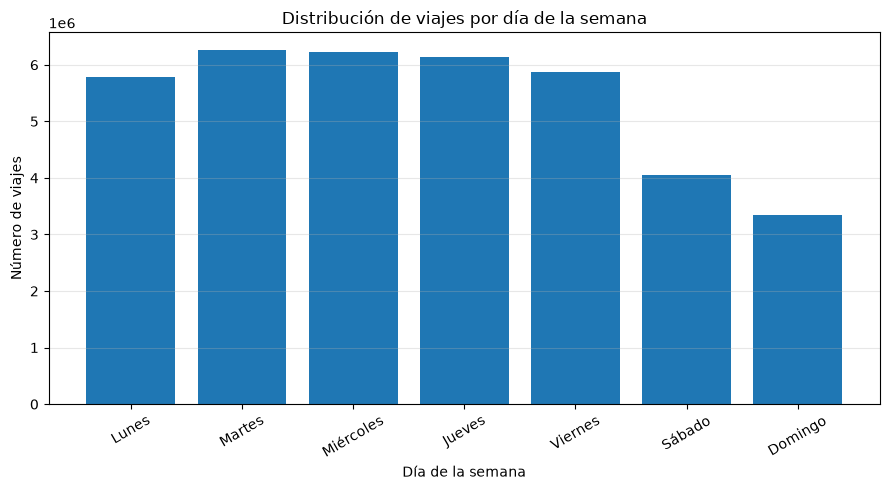

,Dia,Numero_viajes,Porcentaje
0,Lunes,5777720,15.34
1,Martes,6260523,16.63
2,Miércoles,6230030,16.55
3,Jueves,6129014,16.28
4,Viernes,5877581,15.61
5,Sábado,4042277,10.74
6,Domingo,3336729,8.86


In [12]:
# Conteo de viajes por día de la semana
nombres_dias = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo"
]

viajes_p1["Dia_semana"] = (
    viajes_p1["Inicio_del_viaje"].dt.dayofweek
)

viajes_por_dia = (
    viajes_p1.groupby("Dia_semana")
    .size()
    .reindex(range(7), fill_value=0)
)

plt.figure(figsize=(9, 5))
plt.bar(nombres_dias, viajes_por_dia.values)
plt.title("Distribución de viajes por día de la semana")
plt.xlabel("Día de la semana")
plt.ylabel("Número de viajes")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Dia": nombres_dias,
    "Numero_viajes": viajes_por_dia.values,
    "Porcentaje": (
        viajes_por_dia.values / viajes_por_dia.sum() * 100
    ).round(2)
}))

El análisis de los viajes por día de la semana muestra que el uso de MiBici se concentra principalmente de lunes a viernes, que en conjunto representan aproximadamente el 80.41 % de los registros. El martes presenta la mayor proporción de viajes (16.63 %), seguido del miércoles (16.55 %), mientras que el domingo registra la menor actividad (8.86 %). Este comportamiento sugiere que la demanda del sistema está relacionada con patrones de movilidad entre semana, aunque sería necesario analizar otras variables para confirmar las causas. Para el proyecto P1, esta distribución indica que el día de la semana podría ser una variable predictora útil para estimar la demanda por estación.

Análisis de la distribución por hora

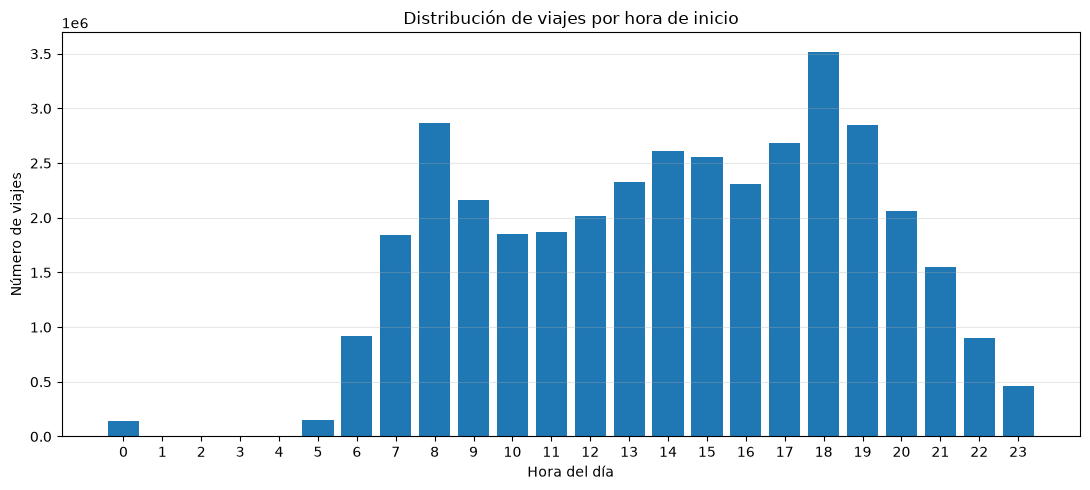

,Hora,Numero_viajes,Porcentaje
0,0,140231,0.37
1,1,296,0.00
2,2,113,0.00
3,3,55,0.00
4,4,82,0.00
5,5,152572,0.41
6,6,914673,2.43
7,7,1846685,4.90
8,8,2863661,7.61
9,9,2162433,5.74


In [13]:
# Conteo de viajes por hora de inicio
viajes_por_hora = (
    viajes_p1["Inicio_del_viaje"]
    .dt.hour
    .value_counts()
    .sort_index()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(11, 5))
plt.bar(viajes_por_hora.index, viajes_por_hora.values)
plt.title("Distribución de viajes por hora de inicio")
plt.xlabel("Hora del día")
plt.ylabel("Número de viajes")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Hora": viajes_por_hora.index,
    "Numero_viajes": viajes_por_hora.values,
    "Porcentaje": (
        viajes_por_hora.values / viajes_por_hora.sum() * 100
    ).round(2)
}))

La distribución de los viajes por hora de inicio presenta variaciones importantes a lo largo del día. La mayor demanda se registra a las 18:00 h, con el 9.35 % de los viajes, seguida de las 8:00 h (7.61 %), las 19:00 h (7.57 %) y las 17:00 h (7.12 %). En contraste, durante la madrugada la actividad es considerablemente menor. Se distinguen periodos de alta demanda por la mañana y por la tarde-noche, posiblemente asociados con los desplazamientos cotidianos. Para el proyecto P1, la hora del día puede ser una variable relevante para predecir la demanda; sin embargo, será necesario analizarla en conjunto con el día de la semana y la estación de origen, ya que los patrones pueden variar entre ubicaciones.

Identificar las estaciones con mayor demanda

,Estacion_Id,Numero_viajes
0,51,809534
1,11,582222
2,50,567589
3,52,547911
4,35,547077
5,54,488867
6,271,461634
7,194,401207
8,75,389285
9,58,351619


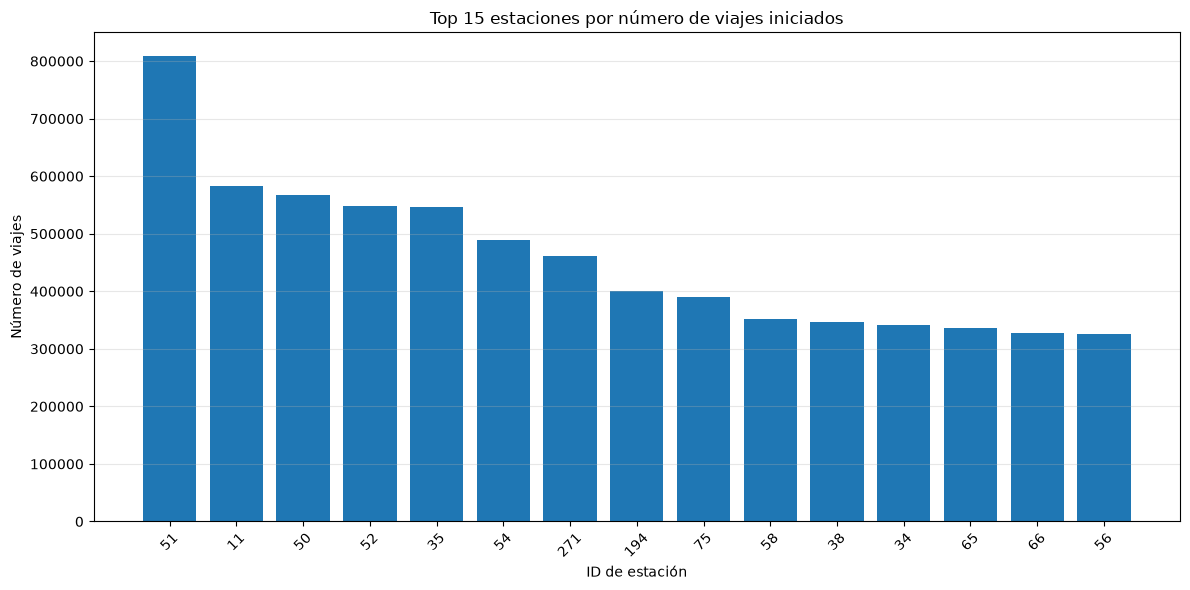

In [14]:
# Número de viajes por estación de origen
viajes_por_estacion = (
    viajes_p1["Origen_Id"]
    .value_counts()
    .rename_axis("Estacion_Id")
    .reset_index(name="Numero_viajes")
)

# Mostrar las 15 estaciones con más viajes
top_15_estaciones = viajes_por_estacion.head(15)

display(top_15_estaciones)

plt.figure(figsize=(12, 6))
plt.bar(
    top_15_estaciones["Estacion_Id"].astype(str),
    top_15_estaciones["Numero_viajes"]
)
plt.title("Top 15 estaciones por número de viajes iniciados")
plt.xlabel("ID de estación")
plt.ylabel("Número de viajes")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

El análisis del número acumulado de viajes por estación de origen muestra diferencias importantes en la demanda dentro del sistema MiBici. La estación 51 presenta el mayor número de viajes iniciados, con 809,534 registros, seguida de las estaciones 11 y 50, con 582,222 y 567,589 viajes, respectivamente. Estos resultados indican que algunas estaciones concentran una mayor proporción de la actividad del sistema. Sin embargo, dado que el conteo incluye todo el periodo de estudio, las diferencias también pueden estar relacionadas con el tiempo que cada estación ha permanecido operativa. Por ello, será necesario complementar este análisis con la ubicación de las estaciones y su evolución temporal para identificar patrones de demanda más representativos.

Identificar las estaciones con menor demanda

,Estacion_Id,Numero_viajes
471,405,2
470,124,19
469,511,112
468,465,124
467,514,152
466,509,170
465,510,173
464,508,213
463,488,224
462,433,274


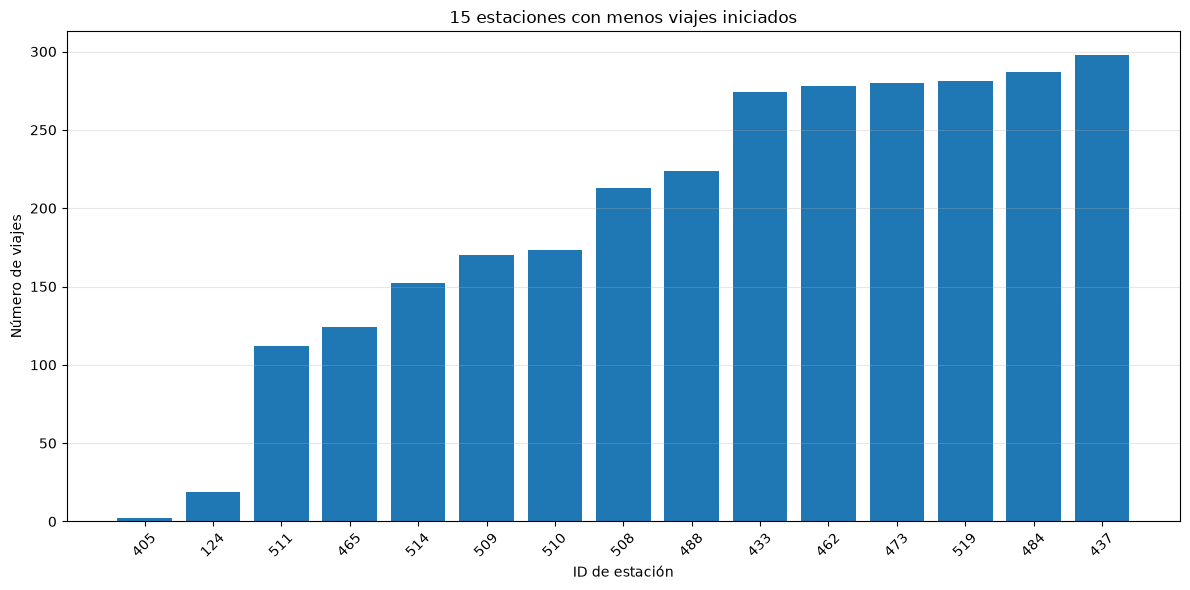

In [15]:
# 15 estaciones con menos viajes iniciados
bottom_15_estaciones = viajes_por_estacion.tail(15).sort_values(
    "Numero_viajes",
    ascending=True
)

display(bottom_15_estaciones)

plt.figure(figsize=(12, 6))
plt.bar(
    bottom_15_estaciones["Estacion_Id"].astype(str),
    bottom_15_estaciones["Numero_viajes"]
)
plt.title("15 estaciones con menos viajes iniciados")
plt.xlabel("ID de estación")
plt.ylabel("Número de viajes")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

El análisis de las estaciones con menor número acumulado de viajes muestra una distribución desigual de la demanda. La estación 405 registra únicamente dos viajes, mientras que las estaciones 124 y 511 presentan 19 y 112 viajes, respectivamente. Estos valores pueden estar relacionados con una actividad realmente baja, con la incorporación reciente de estaciones o con particularidades en los registros. Por tanto, no es posible concluir que estas estaciones tengan una demanda habitual reducida únicamente con el conteo acumulado. Para interpretar adecuadamente los resultados, es necesario revisar la disponibilidad de información de cada estación y analizar su evolución temporal.

In [16]:
# Preparar la nomenclatura para el cruce
nomenclatura_eda = nomenclatura.rename(
    columns={
        "id": "Estacion_Id",
        "name": "Nombre_estacion",
        "dpcapacity": "Capacidad"
    }
)

# Cruzar el top 15 con la nomenclatura
top_15_con_info = top_15_estaciones.merge(
    nomenclatura_eda[
        ["Estacion_Id", "Nombre_estacion", "latitude", "longitude", "Capacidad"]
    ],
    on="Estacion_Id",
    how="left"
)

display(top_15_con_info)

,Estacion_Id,Numero_viajes,Nombre_estacion,latitude,longitude,Capacidad
0,51,809534,(GDL-049) Lopez Cotilla / Penitenciaría,20.674140,-103.355535,39
1,11,582222,(GDL-009) Calz. Federalismo/ C. J. Angulo,20.682077,-103.353835,23
2,50,567589,(GDL-048) C. Constancio Hernández/ Av. Juaréz,20.674721,-103.358548,23
3,52,547911,(GDL-050) C.Pedro Moreno /Federalismo,20.675746,-103.354579,23
4,35,547077,(GDL-033) Av. Hidalgo / C. Pedro Loza,20.677419,-103.347983,15
5,54,488867,(GDL-052) Av. Juarez /16 de Septiembre,20.675244,-103.347889,23
6,271,461634,(GDL-198) Av. Alcalde / C. Hospital,20.685040,-103.347960,31
7,194,401207,(GDL-127) Av. Vallarta / Av. de Los Arcos,20.674380,-103.384880,19
8,75,389285,(GDL-073) Av. La Paz / Av. Federalismo,20.669955,-103.355032,19
9,58,351619,(GDL-056) Av. 16 de Sept. / C. Miguel Blanco,20.671971,-103.347422,19


Estaciones con capacidad disponible: 469
Correlación entre viajes acumulados y capacidad: 0.214


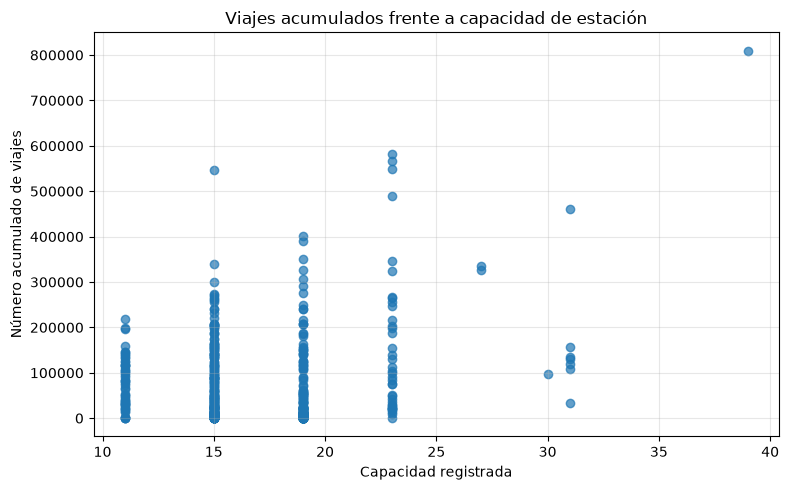

In [17]:
# Conteo de viajes iniciados por estación
demanda_estacion = (
    viajes_p1.groupby("Origen_Id")
    .size()
    .rename("Numero_viajes")
    .reset_index()
    .rename(columns={"Origen_Id": "Estacion_Id"})
)

# Incorporar la capacidad de la nomenclatura
demanda_capacidad = demanda_estacion.merge(
    nomenclatura[["id", "dpcapacity"]].rename(
        columns={"id": "Estacion_Id", "dpcapacity": "Capacidad"}
    ),
    on="Estacion_Id",
    how="left"
)

# Correlación usando únicamente estaciones con capacidad conocida
datos_correlacion = demanda_capacidad.dropna(
    subset=["Capacidad", "Numero_viajes"]
)

correlacion = datos_correlacion[
    ["Numero_viajes", "Capacidad"]
].corr().iloc[0, 1]

print(f"Estaciones con capacidad disponible: {len(datos_correlacion)}")
print(f"Correlación entre viajes acumulados y capacidad: {correlacion:.3f}")

plt.figure(figsize=(8, 5))
plt.scatter(
    datos_correlacion["Capacidad"],
    datos_correlacion["Numero_viajes"],
    alpha=0.7
)
plt.title("Viajes acumulados frente a capacidad de estación")
plt.xlabel("Capacidad registrada")
plt.ylabel("Número acumulado de viajes")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Se analizó la relación entre la capacidad registrada de las estaciones y el número acumulado de viajes iniciados, utilizando 469 estaciones con información disponible. El coeficiente de correlación de Pearson fue de 0.214, lo que indica una asociación lineal positiva débil. Aunque las estaciones con mayor capacidad tienden a registrar más viajes, la relación no es suficientemente fuerte para explicar por sí sola las diferencias de demanda. Además, el conteo acumulado abarca todo el periodo de estudio, mientras que la capacidad corresponde a la nomenclatura de septiembre de 2026. Por ello, los resultados deben interpretarse con cautela, ya que no consideran la antigüedad de cada estación ni los posibles cambios históricos en su capacidad.

Evolución anual de los viajes por estación

In [18]:
# Año de inicio de cada viaje
# Agrupar por año y estación de origen
demanda_anual_estacion = (
    viajes_p1.groupby([
        viajes_p1["Inicio_del_viaje"].dt.year.rename("Anio"),
        "Origen_Id"
    ])
    .size()
    .reset_index(name="Numero_viajes")
    .rename(columns={"Origen_Id": "Estacion_Id"})
)

print("Dimensiones de la tabla:", demanda_anual_estacion.shape)
display(demanda_anual_estacion.head())

Dimensiones de la tabla: (3632, 3)


,Anio,Estacion_Id,Numero_viajes
0,2014,2,231
1,2014,3,215
2,2014,4,273
3,2014,5,104
4,2014,6,165


Selección de las cinco estaciones con más viajes en todo el periodo y compararemos su demanda anual.

Estacion_Id,11,35,50,51,52
Anio,,,,,
2014,362,419,556,598,395
2015,9539,5386,12686,15036,10467
2016,18487,12240,22541,28173,16646
2017,37686,28669,46364,48929,41803
2018,55702,39305,65010,77638,55894
2019,70486,64778,77876,93590,69441
2020,40053,41730,39801,51421,40400
2021,45336,43913,43251,63227,42297
2022,63043,55517,55795,90429,54898


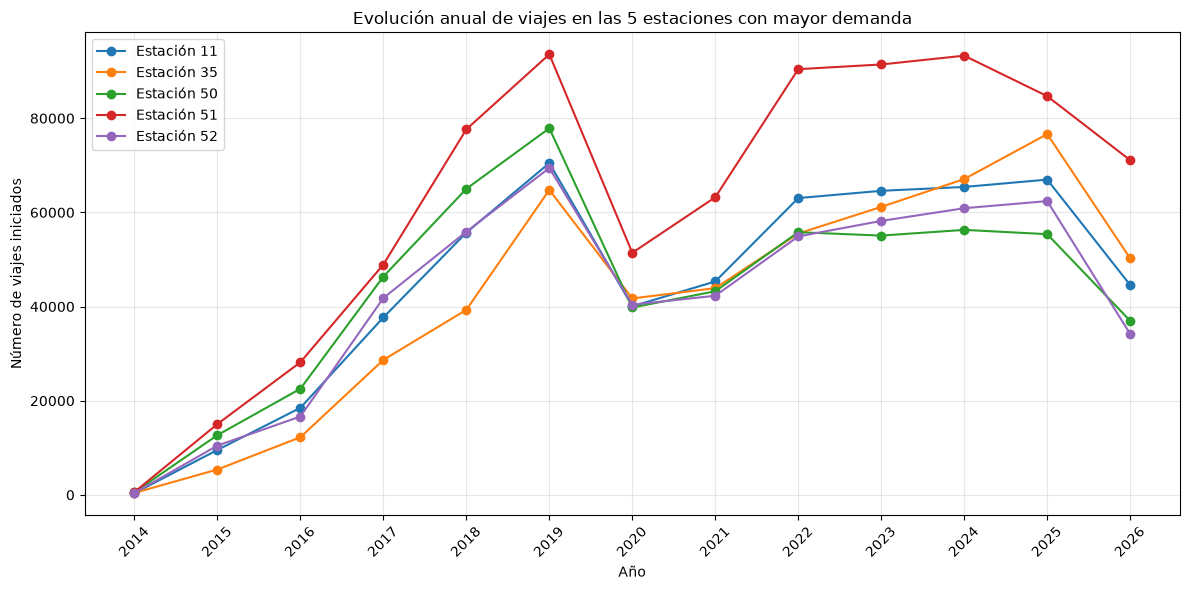

In [19]:
# Obtener las cinco estaciones con más viajes acumulados
top_5_ids = (
    viajes_p1["Origen_Id"]
    .value_counts()
    .head(5)
    .index
)

# Filtrar la tabla anual
top_5_anual = demanda_anual_estacion[
    demanda_anual_estacion["Estacion_Id"].isin(top_5_ids)
].copy()

# Crear tabla para la gráfica
tabla_top_5 = top_5_anual.pivot(
    index="Anio",
    columns="Estacion_Id",
    values="Numero_viajes"
).fillna(0)

display(tabla_top_5)

plt.figure(figsize=(12, 6))

for estacion in tabla_top_5.columns:
    plt.plot(
        tabla_top_5.index,
        tabla_top_5[estacion],
        marker="o",
        label=f"Estación {estacion}"
    )

plt.title("Evolución anual de viajes en las 5 estaciones con mayor demanda")
plt.xlabel("Año")
plt.ylabel("Número de viajes iniciados")
plt.xticks(tabla_top_5.index, rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Comparar la demanda anual total del sistema
Esto ayudará a contextualizar las tendencias de las cinco estaciones respecto al crecimiento general de MiBici.

,Numero_viajes
Inicio_del_viaje,
2014,21655
2015,443115
2016,894898
2017,2407170
2018,3278732
2019,4495135
2020,2773322
2021,3069237
2022,4012697


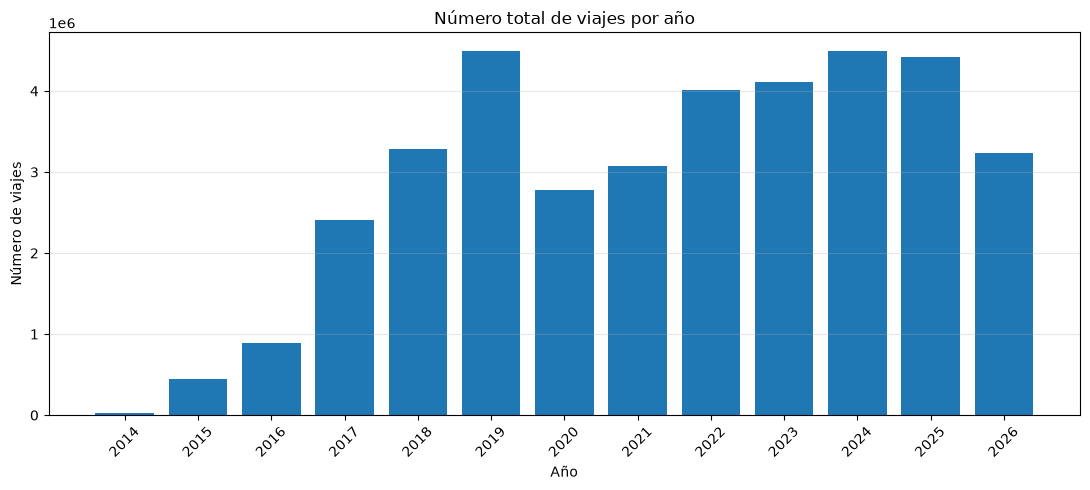

In [20]:
demanda_anual_total = (
    viajes_p1.groupby(viajes_p1["Inicio_del_viaje"].dt.year)
    .size()
    .rename("Numero_viajes")
)

display(demanda_anual_total.to_frame())

plt.figure(figsize=(11, 5))
plt.bar(
    demanda_anual_total.index.astype(str),
    demanda_anual_total.values
)
plt.title("Número total de viajes por año")
plt.xlabel("Año")
plt.ylabel("Número de viajes")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

El análisis de la demanda anual muestra un crecimiento importante del uso de MiBici desde sus primeros años de operación, con una disminución notable en 2020 y una recuperación posterior. El número total de viajes pasó de aproximadamente 4.50 millones en 2019 a 2.77 millones en 2020, para volver a niveles cercanos a 4.50 millones en 2024. Las cinco estaciones con mayor demanda presentan un comportamiento similar, aunque con diferencias en la magnitud y el ritmo de recuperación. La estación 51 destaca por mantener un volumen elevado de viajes durante el periodo analizado, mientras que otras estaciones muestran cambios más marcados en los años recientes. Estos resultados sugieren que el modelo P1 debe considerar tanto la evolución temporal general del sistema como las diferencias de demanda entre estaciones. La interpretación de 2014 y 2026 debe hacerse con cautela, ya que corresponden a periodos parciales.

Comparación de estaciones en términos relativos
Revisión de cómo se distribuyen los viajes entre estaciones en cada año. Así podremos detectar si la demanda está cada vez más concentrada en unas pocas estaciones o si se distribuye de manera más uniforme.

vamos a corregir el filtro para conservar los viajes de menos de 60 segundos, tal como se decidió. Así evitamos que los siguientes resultados se basen en un criterio distinto al que se quiere aplicar.

In [21]:
import gc

# Liberar la versión anterior del DataFrame para reducir el uso de memoria
del viajes_p1
gc.collect()

# Aplicar únicamente los filtros de fecha y estaciones excluidas
mascara_p1 = mascara_fecha & mascara_estaciones

# Crear el conjunto filtrado
viajes_p1 = viajes.loc[mascara_p1].copy()

# Guardar la versión corregida
archivo_p1 = PROCESSED_DATA_DIR / "viajes_p1_filtrados.parquet"
viajes_p1.to_parquet(archivo_p1, index=False)

print(f"Total de viajes conservados: {len(viajes_p1):,}")
print(f"Viajes de menos de 60 segundos: {(mascara_p1 & (duracion < 60)).sum():,}")
print(
    "Viajes con mismo origen y destino:",
    (mascara_p1 & mascara_mismo_origen).sum()
)
print(f"Archivo guardado en: {archivo_p1}")

Total de viajes conservados: 38,920,173
Viajes de menos de 60 segundos: 1,266,299
Viajes con mismo origen y destino: 2718751
Archivo guardado en: C:\Users\ingda\Documents\5_Tec Maestría IA\7_MLOps\Semana 5\equipo52_proyecto_mibici\data\processed\viajes_p1_filtrados.parquet


Demanda relativa por estación y año

In [22]:

# Demanda anual por estación de origen
demanda_anual_estacion = (
    viajes_p1
    .groupby([
        viajes_p1["Inicio_del_viaje"].dt.year.rename("Anio"),
        "Origen_Id"
    ])
    .size()
    .reset_index(name="Numero_viajes")
    .rename(columns={"Origen_Id": "Estacion_Id"})
)

# Total de viajes del sistema en cada año
demanda_anual_estacion["Total_anual"] = (
    demanda_anual_estacion
    .groupby("Anio")["Numero_viajes"]
    .transform("sum")
)

# Porcentaje de la demanda anual correspondiente a cada estación
demanda_anual_estacion["Porcentaje_anual"] = (
    demanda_anual_estacion["Numero_viajes"]
    / demanda_anual_estacion["Total_anual"]
    * 100
)

# Mostrar las estaciones con mayor demanda relativa en cada año
top_estaciones_anual = (
    demanda_anual_estacion
    .sort_values(["Anio", "Porcentaje_anual"], ascending=[True, False])
    .groupby("Anio")
    .head(5)
)

top_estaciones_anual[
    ["Anio", "Estacion_Id", "Numero_viajes", "Porcentaje_anual"]
].round({"Porcentaje_anual": 2})


,Anio,Estacion_Id,Numero_viajes,Porcentaje_anual
71,2014,75,896,3.81
50,2014,54,756,3.21
47,2014,51,677,2.88
46,2014,50,594,2.52
82,2014,86,556,2.36
...,...,...,...,...
3209,2026,51,75141,2.23
3409,2026,271,51877,1.54
3193,2026,35,51759,1.54
3170,2026,11,46677,1.39


Visualizar la evolución de las estaciones principales

Ayuda a entender si la demanda por estación es relativamente estable o cambia con el tiempo. Esa información será relevante cuando definan cómo representar la estación y el periodo temporal para predecir el número de viajes futuros.

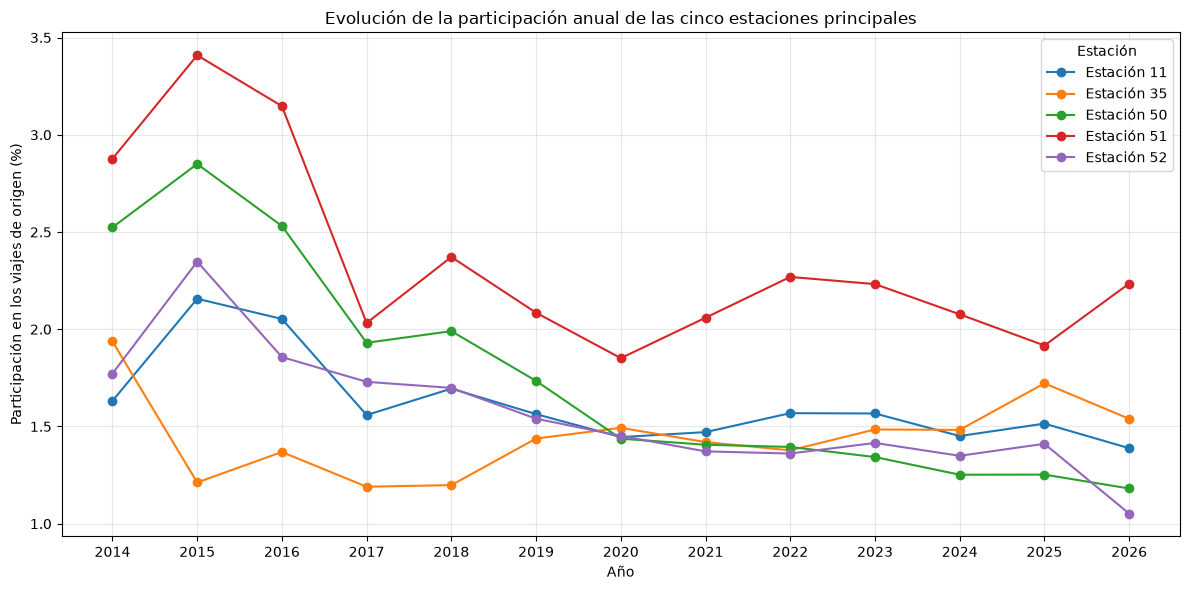

In [23]:

import matplotlib.pyplot as plt

# Identificar las cinco estaciones con más viajes en todo el periodo
top5_ids = (
    viajes_p1["Origen_Id"]
    .value_counts()
    .head(5)
    .index
)

# Filtrar los resultados anuales para esas estaciones
evolucion_top5 = demanda_anual_estacion[
    demanda_anual_estacion["Estacion_Id"].isin(top5_ids)
].copy()

# Gráfica de participación porcentual por año
plt.figure(figsize=(12, 6))

for estacion_id, datos in evolucion_top5.groupby("Estacion_Id"):
    datos = datos.sort_values("Anio")
    plt.plot(
        datos["Anio"],
        datos["Porcentaje_anual"],
        marker="o",
        label=f"Estación {estacion_id}"
    )

plt.title("Evolución de la participación anual de las cinco estaciones principales")
plt.xlabel("Año")
plt.ylabel("Participación en los viajes de origen (%)")
plt.xticks(sorted(evolucion_top5["Anio"].unique()))
plt.legend(title="Estación")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


La evolución de la participación anual muestra que las estaciones principales tuvieron una mayor participación relativa en 2015, seguida de una disminución progresiva hasta 2017. A partir de ese año, la participación se mantiene relativamente estable hasta 2026. La estación 51 destaca por conservar la mayor participación durante el periodo analizado, lo que indica que ha mantenido una posición relevante dentro de la demanda del sistema. Sin embargo, esta tendencia no implica que su número de viajes se haya mantenido constante, sino que su proporción respecto al total anual ha sido comparativamente alta.

Calcular la concentración anual

In [24]:

# Total anual de viajes de origen
total_anual = (
    viajes_p1.groupby(viajes_p1["Inicio_del_viaje"].dt.year)
    .size()
    .rename("Total_viajes")
)

# Viajes anuales por estación de origen
demanda_anual = (
    viajes_p1.assign(
        Anio=viajes_p1["Inicio_del_viaje"].dt.year
    )
    .groupby(["Anio", "Origen_Id"])
    .size()
    .reset_index(name="Numero_viajes")
    .rename(columns={"Origen_Id": "Estacion_Id"})
)

# Obtener la participación de cada estación en el total anual
demanda_anual["Total_anual"] = (
    demanda_anual["Anio"].map(total_anual)
)

demanda_anual["Porcentaje_anual"] = (
    demanda_anual["Numero_viajes"]
    / demanda_anual["Total_anual"]
    * 100
)

# Calcular concentración en las 5 y 10 estaciones principales
resultados_concentracion = []

for anio, grupo in demanda_anual.groupby("Anio"):
    grupo_ordenado = grupo.sort_values(
        "Numero_viajes", ascending=False
    )

    total = grupo_ordenado["Total_anual"].iloc[0]

    top5 = grupo_ordenado.head(5)["Numero_viajes"].sum()
    top10 = grupo_ordenado.head(10)["Numero_viajes"].sum()

    resultados_concentracion.append({
        "Anio": anio,
        "Total_viajes": total,
        "Viajes_top5": top5,
        "Porcentaje_top5": top5 / total * 100,
        "Viajes_top10": top10,
        "Porcentaje_top10": top10 / total * 100
    })

concentracion_anual = pd.DataFrame(resultados_concentracion)

concentracion_anual.round(2)


,Anio,Total_viajes,Viajes_top5,Porcentaje_top5,Viajes_top10,Porcentaje_top10
0,2014,23534,3479,14.78,5931,25.20
1,2015,459829,62248,13.54,109731,23.86
2,2016,921801,108349,11.75,182970,19.85
3,2017,2464492,216600,8.79,369979,15.01
4,2018,3363131,313280,9.32,528846,15.72
5,2019,4622801,390987,8.46,687963,14.88
6,2020,2861966,222784,7.78,402848,14.08
7,2021,3181220,252605,7.94,438361,13.78
8,2022,4197761,340674,8.12,572309,13.63
9,2023,4288022,354033,8.26,580881,13.55


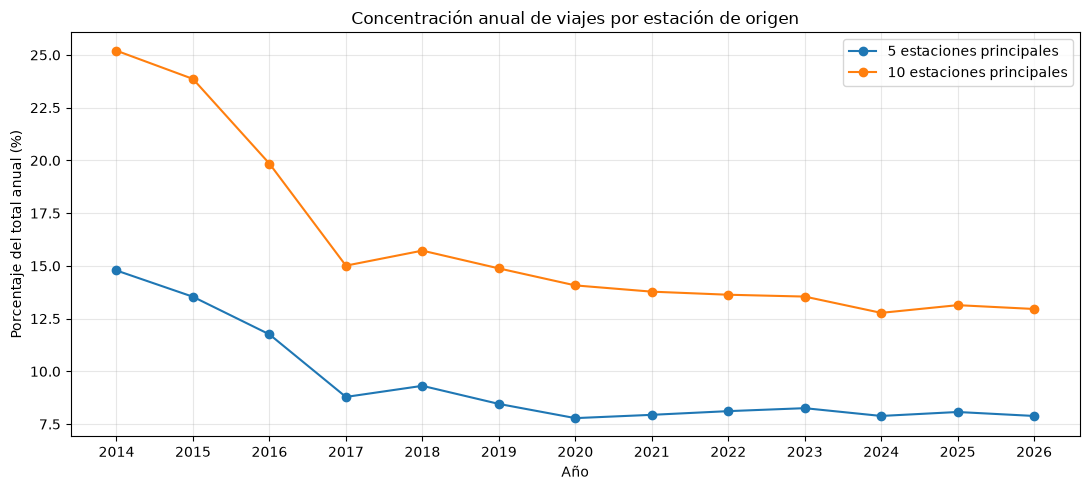

In [25]:
plt.figure(figsize=(11, 5))

plt.plot(
    concentracion_anual["Anio"],
    concentracion_anual["Porcentaje_top5"],
    marker="o",
    label="5 estaciones principales"
)

plt.plot(
    concentracion_anual["Anio"],
    concentracion_anual["Porcentaje_top10"],
    marker="o",
    label="10 estaciones principales"
)

plt.title("Concentración anual de viajes por estación de origen")
plt.xlabel("Año")
plt.ylabel("Porcentaje del total anual (%)")
plt.xticks(concentracion_anual["Anio"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


El análisis de concentración anual muestra que la participación de las cinco estaciones con mayor demanda disminuyó de 14.78% en 2014 a alrededor de 8% en los años recientes. De forma similar, la participación de las diez principales pasó de 25.20% a cerca de 13%. Esta tendencia sugiere que, con el tiempo, los viajes se han distribuido relativamente más entre las estaciones del sistema, en lugar de concentrarse en un grupo reducido. No obstante, los años 2014 y 2026 son periodos parciales, por lo que sus resultados deben interpretarse con cautela. Este hallazgo es relevante para P1 porque respalda la necesidad de considerar las diferencias entre estaciones al analizar y predecir la demanda.

Análisis día de la semana y hora en conjunto

In [27]:
# Crear las columnas temporales que necesita el análisis
viajes_p1["Dia_semana"] = viajes_p1["Inicio_del_viaje"].dt.dayofweek
viajes_p1["Hora"] = viajes_p1["Inicio_del_viaje"].dt.hour

In [28]:
# Calcular los viajes por día de la semana y hora
demanda_dia_hora = (
    viajes_p1
    .groupby(["Dia_semana", "Hora"])
    .size()
    .reset_index(name="Numero_viajes")
)

# Crear la tabla que utiliza tu gráfica
tabla_dia_hora = demanda_dia_hora.pivot(
    index="Dia_semana",
    columns="Hora",
    values="Numero_viajes"
)

# Mantener el orden de lunes a domingo
tabla_dia_hora = tabla_dia_hora.reindex(range(7))

tabla_dia_hora.index = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo"
]

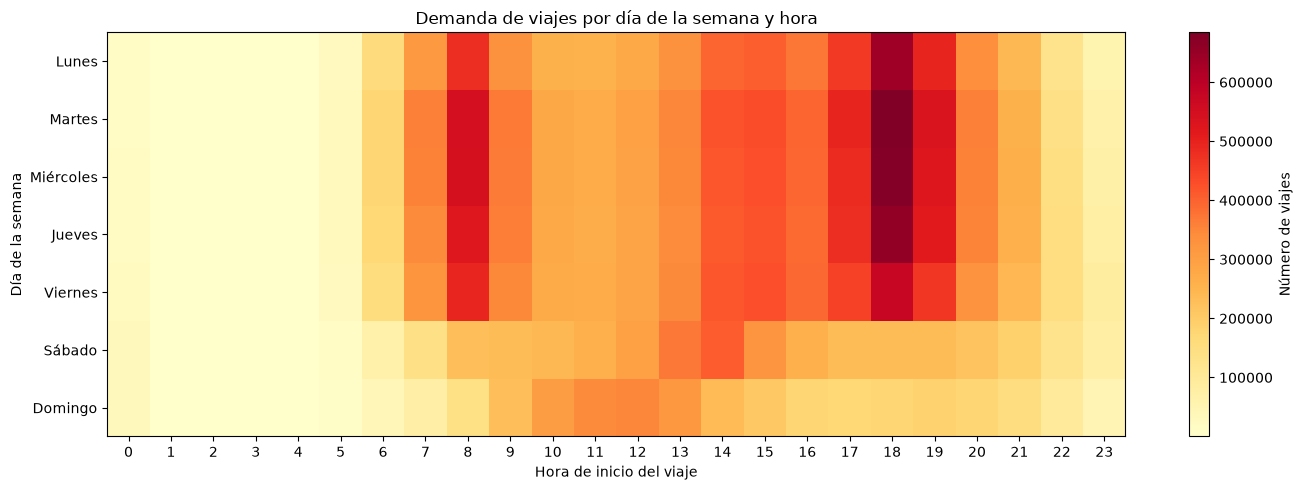

In [29]:

plt.figure(figsize=(14, 5))

plt.imshow(
    tabla_dia_hora,
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest"
)

plt.colorbar(label="Número de viajes")
plt.title("Demanda de viajes por día de la semana y hora")
plt.xlabel("Hora de inicio del viaje")
plt.ylabel("Día de la semana")

plt.xticks(
    range(len(tabla_dia_hora.columns)),
    tabla_dia_hora.columns
)
plt.yticks(
    range(len(tabla_dia_hora.index)),
    tabla_dia_hora.index
)

plt.tight_layout()
plt.show()


El análisis conjunto de la demanda por día de la semana y hora de inicio muestra patrones horarios diferenciados. De lunes a viernes, los principales picos se presentan a las 8:00 y a las 18:00 horas, con una demanda también elevada a las 7:00 y 9:00 horas, así como entre las 13:00 y las 19:00 horas. Este comportamiento podría estar relacionado con los desplazamientos laborales y escolares, aunque esa relación no puede confirmarse únicamente con los datos disponibles. Los sábados, el pico de demanda se presenta alrededor de las 14:00 horas, mientras que los domingos la actividad es menor y muestra un ligero incremento entre las 11:00 y las 12:00 horas. Estos resultados sugieren que el día de la semana y la hora son variables relevantes para analizar y predecir la demanda de viajes por estación.

In [30]:

# Verificar el conjunto de datos que utilizaremos
print(f"Registros: {len(viajes_p1):,}")
print(f"Columnas: {viajes_p1.shape[1]:,}")
print(f"Fecha inicial: {viajes_p1['Inicio_del_viaje'].min()}")
print(f"Fecha final: {viajes_p1['Inicio_del_viaje'].max()}")

# Verificar que las variables temporales estén disponibles
columnas_temporales = ["Anio", "Mes", "Dia_semana", "Hora"]
print("\nVariables temporales disponibles:")
print([col for col in columnas_temporales if col in viajes_p1.columns])


Registros: 38,920,173
Columnas: 7
Fecha inicial: 2014-12-01 00:33:47
Fecha final: 2026-09-30 23:59:48

Variables temporales disponibles:
['Dia_semana', 'Hora']
